# 🔬 2D Plasticity Benchmark: Exploratory Data Analysis & Diagnostics
**Project:** Guided Research: Neural Operators & Transformer Surrogates for Plasticity (TUM)  
**Dataset:** Geo-FNO Non-linear Solid Mechanics Benchmark (`plas_N987_T20.mat`)  
**Processed Directory:** `data/processed/plasticity/`

---

### Benchmark Problem Context
This benchmark simulates an elasto-plastic solid mechanics forging scenario:
- A 2D material block $\Omega = [0, L] \times [0, H]$ ($L = 50\text{ mm}$, $H = 15\text{ mm}$) is compressed from above by a frictionless rigid die.
- The die geometry is parameterized by a cubic Hermite spline $S_d(x)$ across the top boundary.
- The block is clamped at the bottom edge ($y \approx 0$).
- Material model: Isotropic stiffness tensor ($E = 200\text{ GPa}$, $\nu = 0.3$), yield strength $\sigma_Y = 70\text{ MPa}$, density $\rho = 7850\text{ kg}\cdot\text{m}^{-3}$.
- Spatial discretization: $101 \times 31 = 3,131$ quadrilateral grid nodes.
- Temporal rollout: $T = 20$ time increments.
- Total samples: 987 (900 train, 7 validation, 80 test).

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

# Add repository root to path for src package imports
WORKSPACE_ROOT = Path(".").resolve().parent.parent
if str(WORKSPACE_ROOT) not in sys.path:
    sys.path.insert(0, str(WORKSPACE_ROOT))

# Matplotlib styling
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 140

print("Environment configured successfully!")
print(f"Workspace Root: {WORKSPACE_ROOT}")

Environment configured successfully!
Workspace Root: /home/arturobaltanas/University/Guided Research


## 1. Dataset Loading & Partition Verification
Load the clean, standardized NumPy archives (`.npz`) and companion metadata generated by `BaseDatasetProcessor`.

In [2]:
DATA_DIR = Path("../../data/processed/plasticity").resolve()

# Load partitions
train_data = dict(np.load(DATA_DIR / "train.npz"))
val_data = dict(np.load(DATA_DIR / "val.npz"))
test_data = dict(np.load(DATA_DIR / "test.npz"))

with open(DATA_DIR / "stats.json", "r") as f:
    stats = json.load(f)

with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

print("=" * 65)
print("             DATASET PARTITION SUMMARY CARD              ")
print("=" * 65)
print(f"Dataset Name:     {metadata['dataset_name']}")
print(f"Physical Problem: {metadata['physical_problem']}")
print(f"Train Partition:  {train_data['die_profile'].shape[0]} samples")
print(f"Val Partition:    {val_data['die_profile'].shape[0]} samples")
print(f"Test Partition:   {test_data['die_profile'].shape[0]} samples")
print(f"Spatial Grid:     {metadata['spatial_dimensions']['nx']} x {metadata['spatial_dimensions']['ny']} (Total = {metadata['spatial_dimensions']['nx'] * metadata['spatial_dimensions']['ny']} nodes)")
print(f"Timesteps:        {metadata['temporal_dimensions']['num_timesteps']}")
print("-" * 65)
print("Array Shapes (Train):")
for k, v in train_data.items():
    print(f"  - {k:<16}: shape={str(v.shape):<24} dtype={v.dtype}")
print("=" * 65)

             DATASET PARTITION SUMMARY CARD              
Dataset Name:     Geo-FNO Plasticity Benchmark
Physical Problem: 2D Elastoplastic Forging under Rigid Moving Die
Train Partition:  900 samples
Val Partition:    7 samples
Test Partition:   80 samples
Spatial Grid:     101 x 31 (Total = 3131 nodes)
Timesteps:        20
-----------------------------------------------------------------
Array Shapes (Train):
  - die_profile     : shape=(900, 101)               dtype=float32
  - die_boundary    : shape=(900, 101, 2)            dtype=float32
  - coords          : shape=(900, 101, 31, 20, 2)    dtype=float32
  - coords_initial  : shape=(900, 101, 31, 2)        dtype=float32
  - displacements   : shape=(900, 101, 31, 20, 2)    dtype=float32
  - target_all      : shape=(900, 101, 31, 20, 4)    dtype=float32
  - time_steps      : shape=(20,)                    dtype=float32


## 2. Continuum Mechanics & Kinematic Invariance
In continuum mechanics, the deformed coordinates $\mathbf{x}(t)$ must strictly equal the reference undeformed configuration $\mathbf{X}_0$ plus the displacement vector $\mathbf{u}(t)$:
$$\mathbf{x}(t) = \mathbf{X}_0 + \mathbf{u}(t) \iff \mathbf{X}_{\text{undeformed}} = \mathbf{x}(t) - \mathbf{u}(t) = \text{const}$$

We verify this identity across all 900 training instances and all 20 time increments.

In [3]:
coords = train_data["coords"]            # (900, 101, 31, 20, 2)
displacements = train_data["displacements"] # (900, 101, 31, 20, 2)

# Compute reconstructed reference configuration for all t
reconstructed_x0 = coords[..., 0] - displacements[..., 0] # (900, 101, 31, 20)
reconstructed_y0 = coords[..., 1] - displacements[..., 1] # (900, 101, 31, 20)

# Check variation over the time axis (ptp = peak-to-peak: max - min)
time_variation_x = np.ptp(reconstructed_x0, axis=-1).max()
time_variation_y = np.ptp(reconstructed_y0, axis=-1).max()

# Check bottom boundary clamping (ny index -1 in dataset, y ≈ -0.1 mm)
bottom_uy_max = np.abs(displacements[:, :, -1, :, 1]).max()

print("=" * 65)
print("         PHYSICAL & KINEMATIC CONSISTENCY AUDIT          ")
print("=" * 65)
print(f"Reference X Invariance Across All t: {time_variation_x:.6e} mm (Machine precision: PASS)")
print(f"Reference Y Invariance Across All t: {time_variation_y:.6e} mm (Machine precision: PASS)")
print(f"Bottom Boundary Vertical Displ. uy: {bottom_uy_max:.6e} mm (Strictly clamped: PASS)")
print("=" * 65)

         PHYSICAL & KINEMATIC CONSISTENCY AUDIT          
Reference X Invariance Across All t: 3.433228e-05 mm (Machine precision: PASS)
Reference Y Invariance Across All t: 8.583069e-06 mm (Machine precision: PASS)
Bottom Boundary Vertical Displ. uy: 0.000000e+00 mm (Strictly clamped: PASS)


## 3. Die Boundary Profile Variations ($S_d(x)$)
The input to the surrogate model is the 1D parameterization of the rigid die $S_d(x)$, sampled across 101 horizontal points.
Below, we visualize the envelope, statistical dispersion, and individual sample profiles.

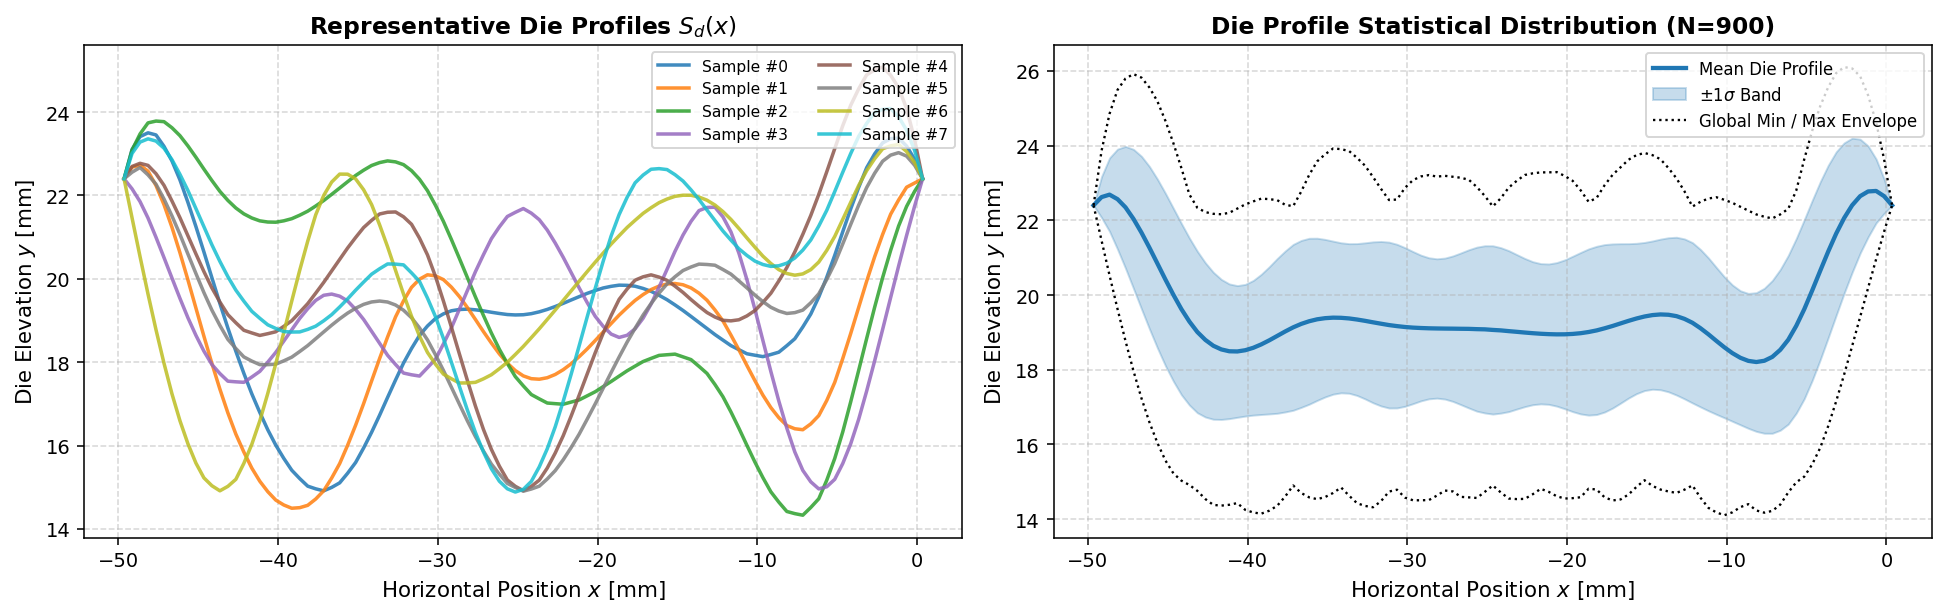

In [4]:
die_boundary = train_data["die_boundary"]  # (900, 101, 2)
x_coords = die_boundary[0, :, 0]           # (101,)
die_heights = die_boundary[:, :, 1]        # (900, 101)

mean_profile = np.mean(die_heights, axis=0)
std_profile = np.std(die_heights, axis=0)
min_profile = np.min(die_heights, axis=0)
max_profile = np.max(die_heights, axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Representative Sample Curves
colors = plt.cm.tab10(np.linspace(0, 1, 8))
for i in range(8):
    ax1.plot(x_coords, die_heights[i], label=f"Sample #{i}", color=colors[i], linewidth=1.8, alpha=0.85)

ax1.set_title("Representative Die Profiles $S_d(x)$", fontweight="bold")
ax1.set_xlabel("Horizontal Position $x$ [mm]")
ax1.set_ylabel("Die Elevation $y$ [mm]")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right", ncol=2, fontsize=8)

# Plot 2: Statistical Envelope
ax2.plot(x_coords, mean_profile, color="#1f77b4", linewidth=2.2, label="Mean Die Profile")
ax2.fill_between(x_coords, mean_profile - std_profile, mean_profile + std_profile, color="#1f77b4", alpha=0.25, label=r"$\pm 1\sigma$ Band")
ax2.plot(x_coords, min_profile, color="black", linestyle=":", linewidth=1.2, label="Global Min / Max Envelope")
ax2.plot(x_coords, max_profile, color="black", linestyle=":", linewidth=1.2)

ax2.set_title("Die Profile Statistical Distribution (N=900)", fontweight="bold")
ax2.set_xlabel("Horizontal Position $x$ [mm]")
ax2.set_ylabel("Die Elevation $y$ [mm]")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

## 4. Spatiotemporal Mesh Deformation Dynamics
Visualizing the spatial mesh wireframe and displacement field $|\mathbf{u}|$ evolution across 5 progressive time steps ($t \in [0, 5, 10, 15, 19]$) for a chosen sample.

/tmp/ipykernel_74517/99904436.py:18: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = ax.pcolormesh(x_grid, y_grid, mag_grid, cmap="viridis", vmin=0.0, vmax=vmax, shading="auto")


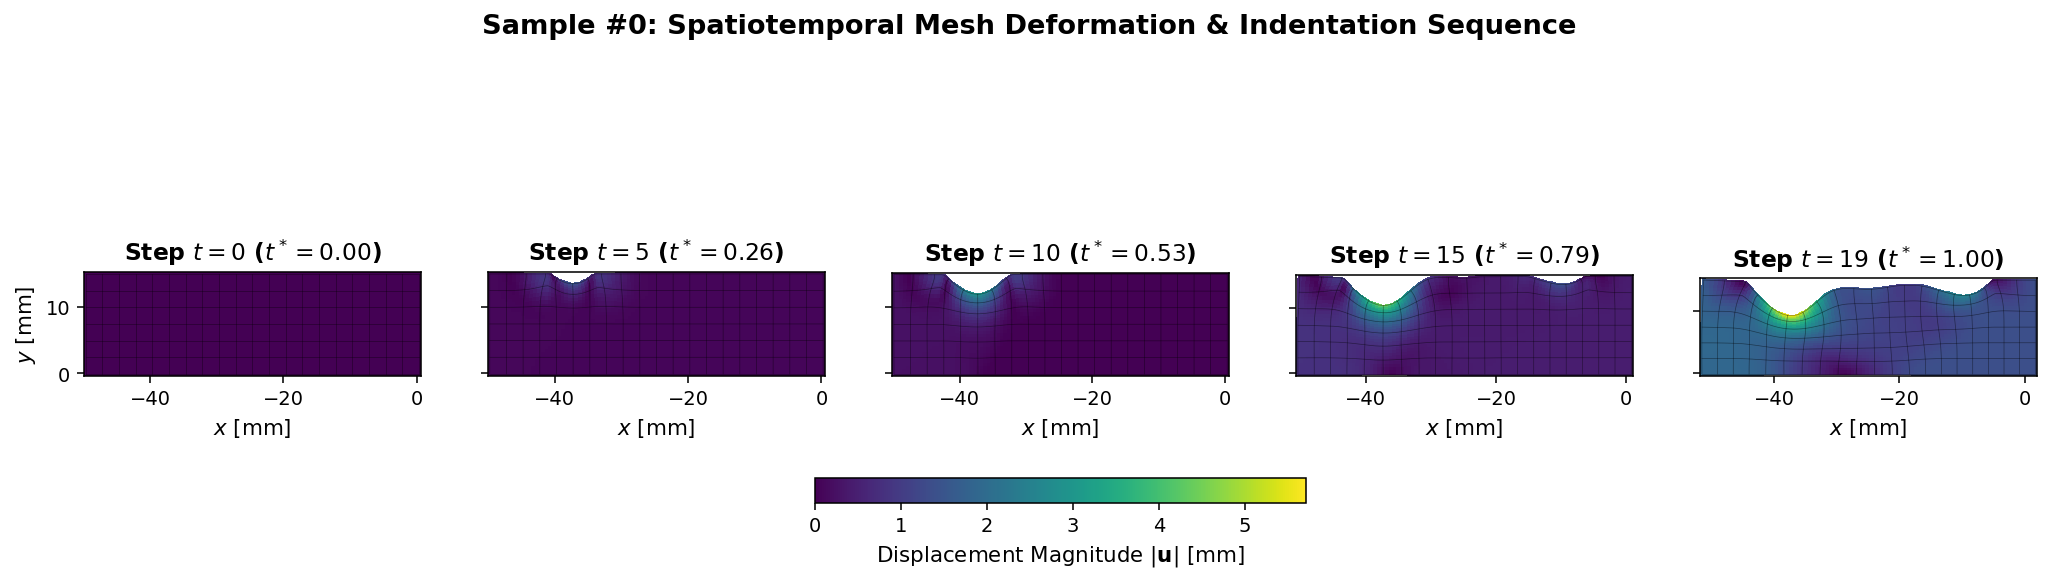

In [5]:
sample_idx = 0
sample_coords = coords[sample_idx]              # (101, 31, 20, 2)
sample_disp = displacements[sample_idx]          # (101, 31, 20, 2)
sample_mag = np.linalg.norm(sample_disp, axis=-1) # (101, 31, 20)

selected_steps = [0, 5, 10, 15, 19]
fig, axes = plt.subplots(1, len(selected_steps), figsize=(18, 3.8), sharey=True)

vmax = float(sample_mag.max())

for ax_idx, t_step in enumerate(selected_steps):
    ax = axes[ax_idx]
    x_grid = sample_coords[:, :, t_step, 0]
    y_grid = sample_coords[:, :, t_step, 1]
    mag_grid = sample_mag[:, :, t_step]
    
    # Heatmap of displacement magnitude
    im = ax.pcolormesh(x_grid, y_grid, mag_grid, cmap="viridis", vmin=0.0, vmax=vmax, shading="auto")
    
    # Subsampled wireframe lines
    for i in range(0, x_grid.shape[0], 5):
        ax.plot(x_grid[i, :], y_grid[i, :], color="black", linewidth=0.35, alpha=0.45)
    for j in range(0, x_grid.shape[1], 5):
        ax.plot(x_grid[:, j], y_grid[:, j], color="black", linewidth=0.35, alpha=0.45)
        
    ax.set_title(f"Step $t={t_step}$ ($t^*={t_step/19:.2f}$)", fontweight="bold")
    ax.set_xlabel("$x$ [mm]")
    if ax_idx == 0:
        ax.set_ylabel("$y$ [mm]")
    ax.set_aspect("equal", "box")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="horizontal", fraction=0.06, pad=0.25)
cbar.set_label(r"Displacement Magnitude $|\mathbf{u}|$ [mm]", fontsize=11)

fig.suptitle(f"Sample #{sample_idx}: Spatiotemporal Mesh Deformation & Indentation Sequence", fontsize=14, fontweight="bold", y=1.03)
plt.show()

## 5. Flow of Material: Quiver Vector Field & Component Heatmaps
Inspecting directional flow vectors $\mathbf{u} = (u_x, u_y)$ under die indentation. The downward motion of the rigid die forces the elastoplastic material to displace both downwards and outward toward the lateral unconstrained edges.

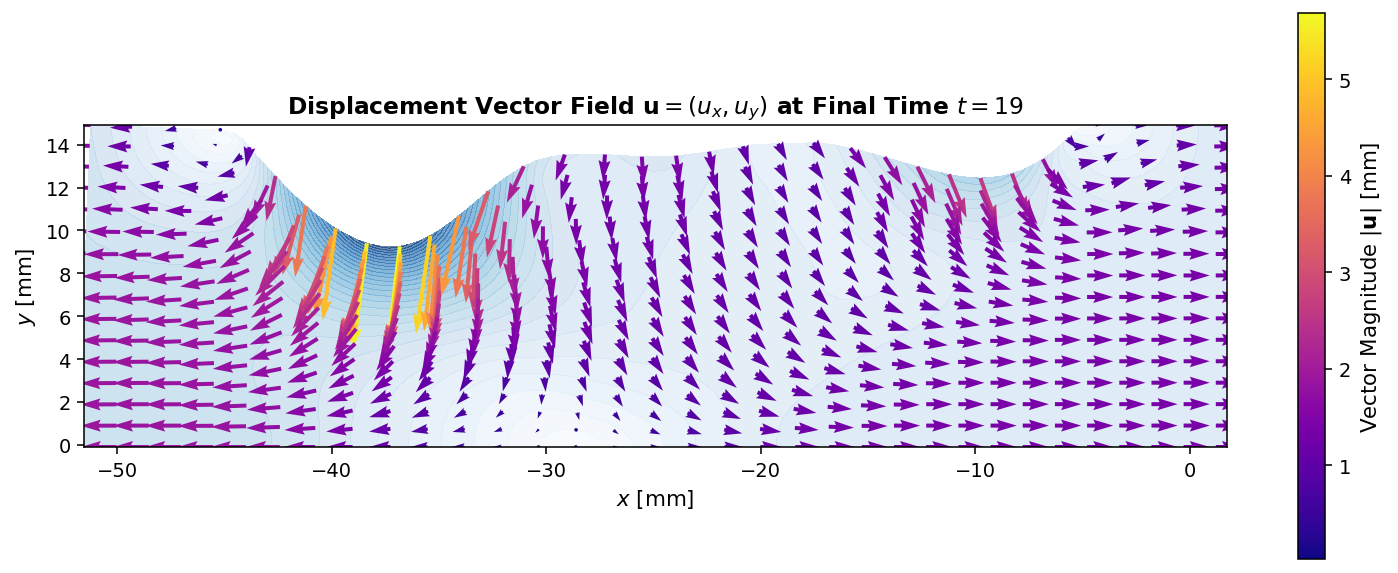

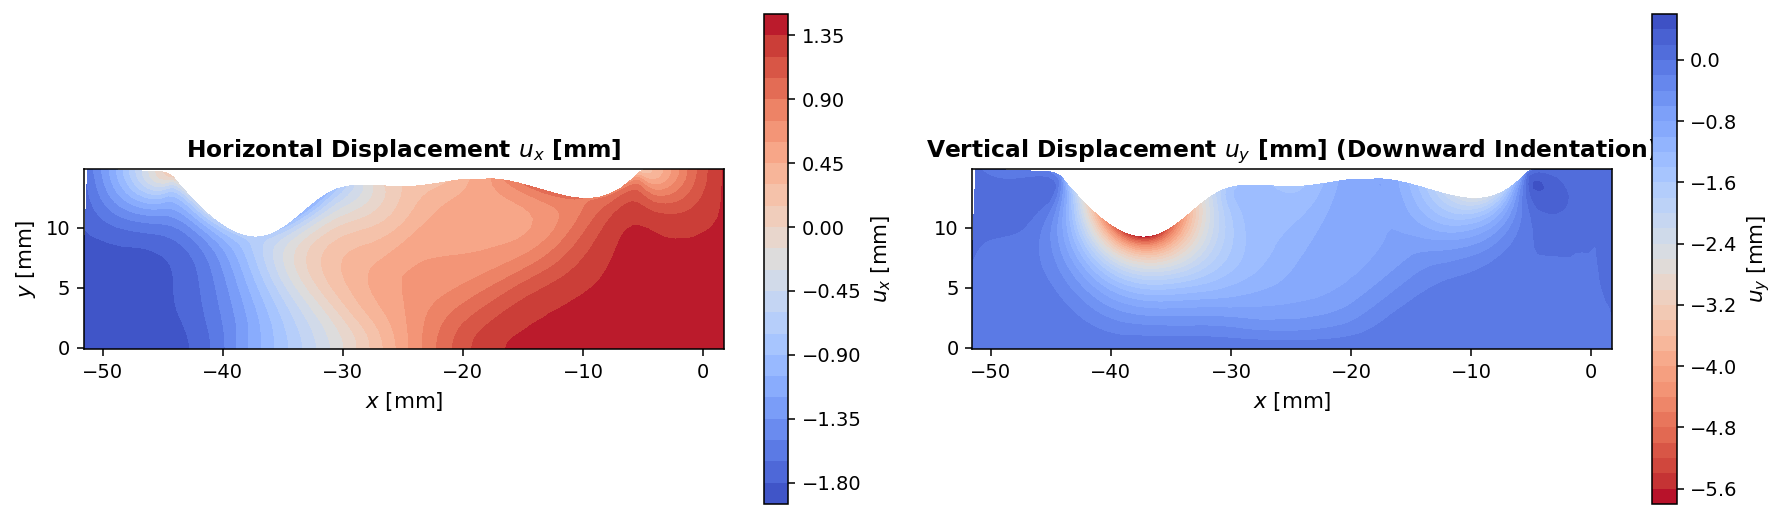

In [6]:
t_final = 19
x_final = sample_coords[:, :, t_final, 0]
y_final = sample_coords[:, :, t_final, 1]
ux_final = sample_disp[:, :, t_final, 0]
uy_final = sample_disp[:, :, t_final, 1]
mag_final = sample_mag[:, :, t_final]

# Subplot 1: Vector Field (Quiver)
fig_q, ax_quiver = plt.subplots(figsize=(11, 4.2))
stride = (3, 2)
sub_x = x_final[::stride[0], ::stride[1]]
sub_y = y_final[::stride[0], ::stride[1]]
sub_ux = ux_final[::stride[0], ::stride[1]]
sub_uy = uy_final[::stride[0], ::stride[1]]
sub_mag = mag_final[::stride[0], ::stride[1]]

cf_bg = ax_quiver.contourf(x_final, y_final, mag_final, levels=30, cmap="Blues", alpha=0.6)
q = ax_quiver.quiver(sub_x, sub_y, sub_ux, sub_uy, sub_mag, cmap="plasma", scale=60, width=0.0035)

ax_quiver.set_title(r"Displacement Vector Field $\mathbf{u} = (u_x, u_y)$ at Final Time $t=19$", fontweight="bold")
ax_quiver.set_xlabel("$x$ [mm]")
ax_quiver.set_ylabel("$y$ [mm]")
ax_quiver.set_aspect("equal")
fig_q.colorbar(q, ax=ax_quiver, label=r"Vector Magnitude $|\mathbf{u}|$ [mm]")
plt.tight_layout()
plt.show()

# Subplot 2: Horizontal vs Vertical Components Side-by-Side
fig_sub, (ax_ux, ax_uy) = plt.subplots(1, 2, figsize=(13, 3.8))

cf_ux = ax_ux.contourf(x_final, y_final, ux_final, levels=30, cmap="coolwarm")
ax_ux.set_title(r"Horizontal Displacement $u_x$ [mm]", fontweight="bold")
ax_ux.set_xlabel("$x$ [mm]")
ax_ux.set_ylabel("$y$ [mm]")
ax_ux.set_aspect("equal")
fig_sub.colorbar(cf_ux, ax=ax_ux, label="$u_x$ [mm]")

cf_uy = ax_uy.contourf(x_final, y_final, uy_final, levels=30, cmap="coolwarm_r")
ax_uy.set_title(r"Vertical Displacement $u_y$ [mm] (Downward Indentation)", fontweight="bold")
ax_uy.set_xlabel("$x$ [mm]")
ax_uy.set_aspect("equal")
fig_sub.colorbar(cf_uy, ax=ax_uy, label="$u_y$ [mm]")

plt.tight_layout()
plt.show()

## 6. Multi-Sample Comparison Under Distinct Die Geometries
Comparing how different die geometries induce distinct indentation depths and plastic deformation profiles across 3 different samples.

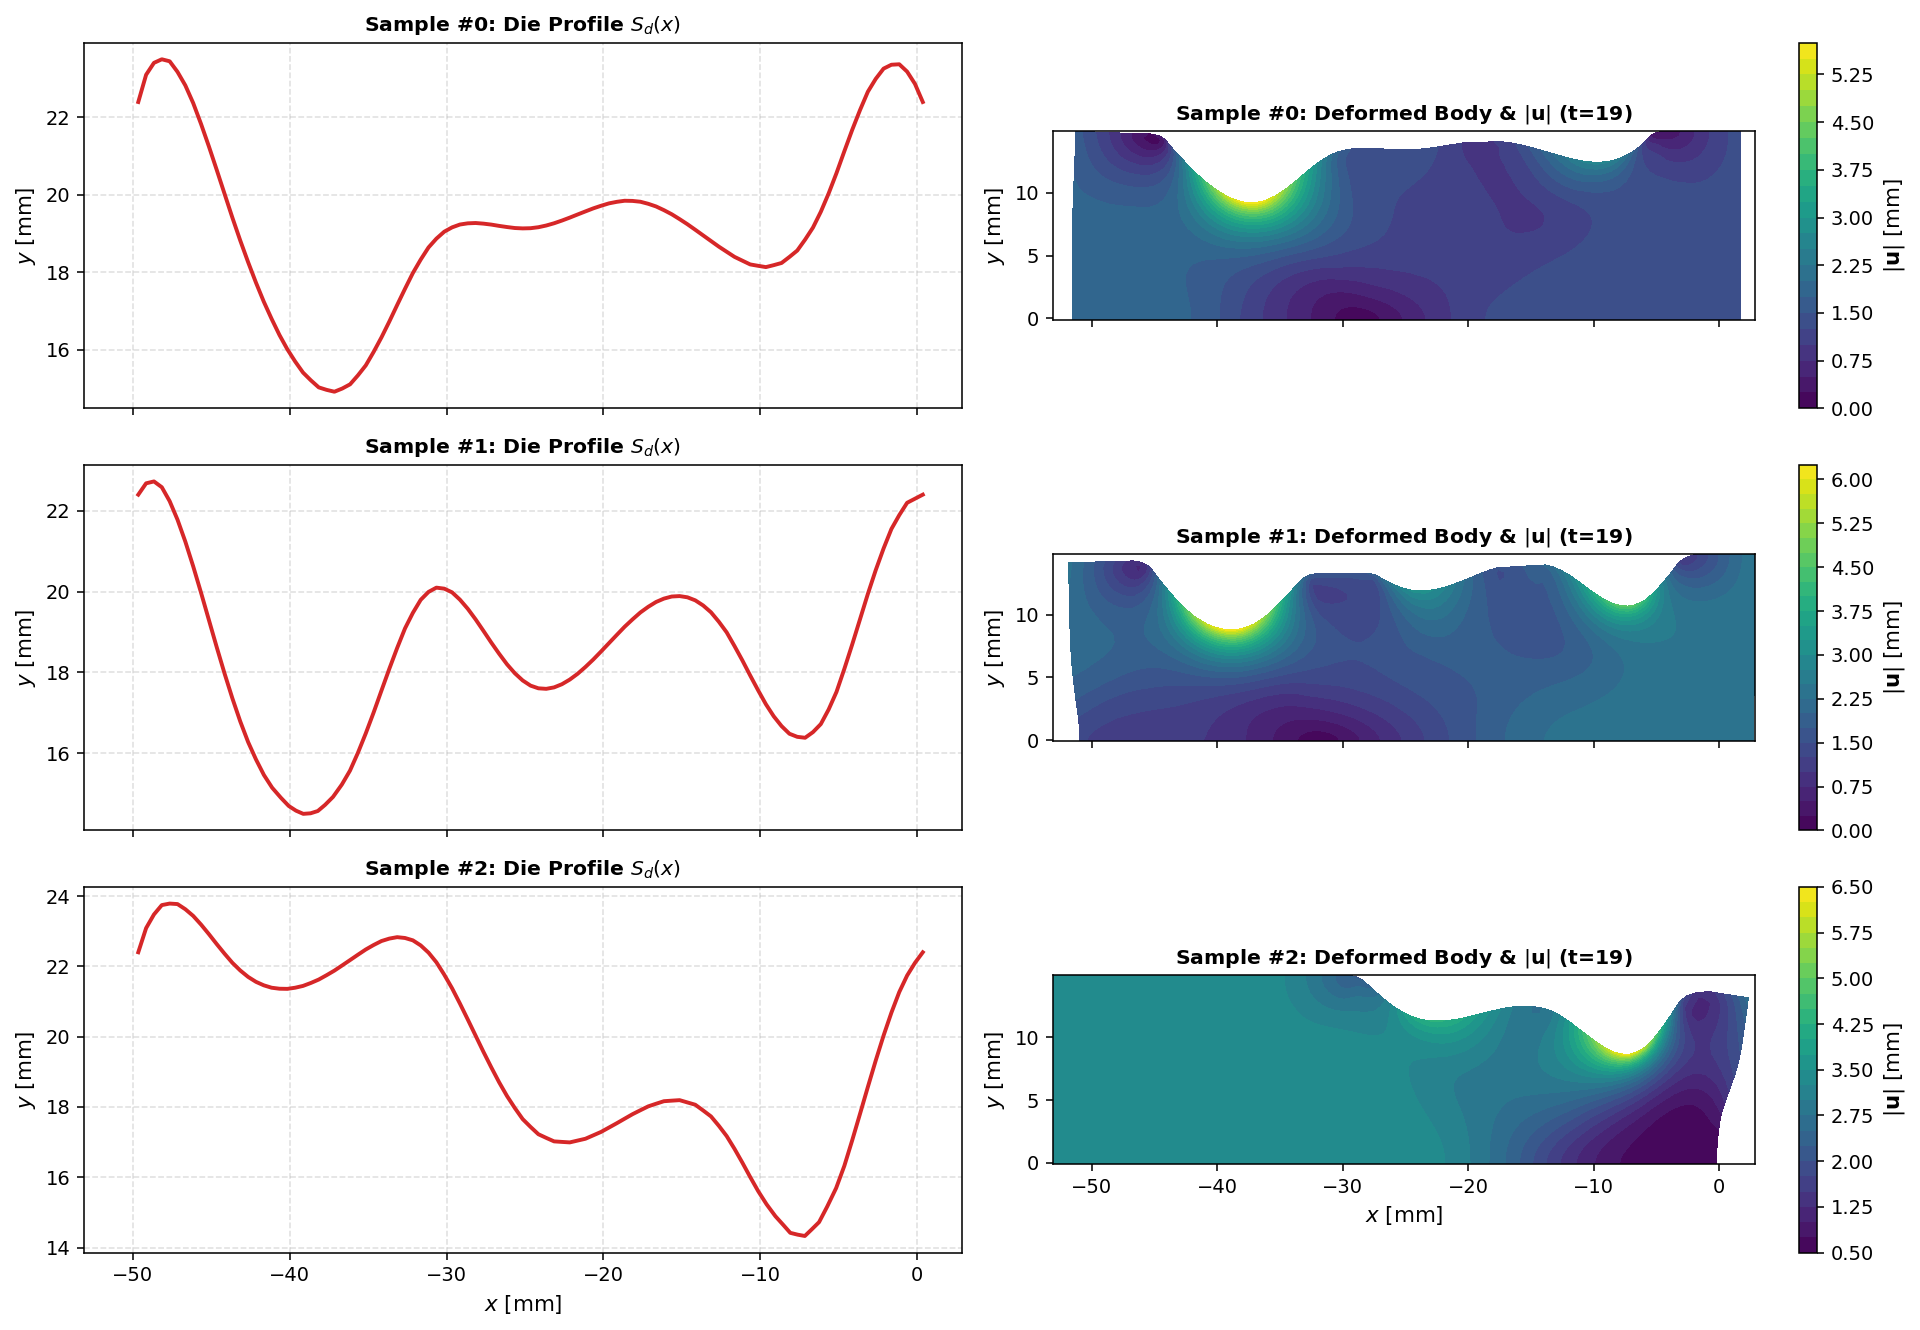

In [7]:
compare_samples = [0, 1, 2]
fig, axes = plt.subplots(len(compare_samples), 2, figsize=(14, 3.2 * len(compare_samples)), sharex=True)

for row, s_idx in enumerate(compare_samples):
    s_die_x = die_boundary[s_idx, :, 0]
    s_die_y = die_boundary[s_idx, :, 1]
    
    s_x = coords[s_idx, :, :, 19, 0]
    s_y = coords[s_idx, :, :, 19, 1]
    s_u = np.linalg.norm(displacements[s_idx, :, :, 19, :], axis=-1)
    
    # Left column: Die profile
    axes[row, 0].plot(s_die_x, s_die_y, color="#d62728", linewidth=2.0)
    axes[row, 0].set_title(f"Sample #{s_idx}: Die Profile $S_d(x)$", fontweight="bold", fontsize=10.5)
    axes[row, 0].set_ylabel("$y$ [mm]")
    axes[row, 0].grid(True, linestyle="--", alpha=0.4)
    
    # Right column: Deformed mesh & displacement
    cf = axes[row, 1].contourf(s_x, s_y, s_u, levels=25, cmap="viridis")
    axes[row, 1].set_title(f"Sample #{s_idx}: Deformed Body & " + r"$|\mathbf{u}|$ (t=19)", fontweight="bold", fontsize=10.5)
    axes[row, 1].set_ylabel("$y$ [mm]")
    axes[row, 1].set_aspect("equal")
    fig.colorbar(cf, ax=axes[row, 1], label=r"$|\mathbf{u}|$ [mm]")

axes[-1, 0].set_xlabel("$x$ [mm]")
axes[-1, 1].set_xlabel("$x$ [mm]")
plt.tight_layout()
plt.show()

## 7. Global Dataset Feature Distributions
Statistical distribution of displacements, coordinates, and die heights across all 900 training instances.

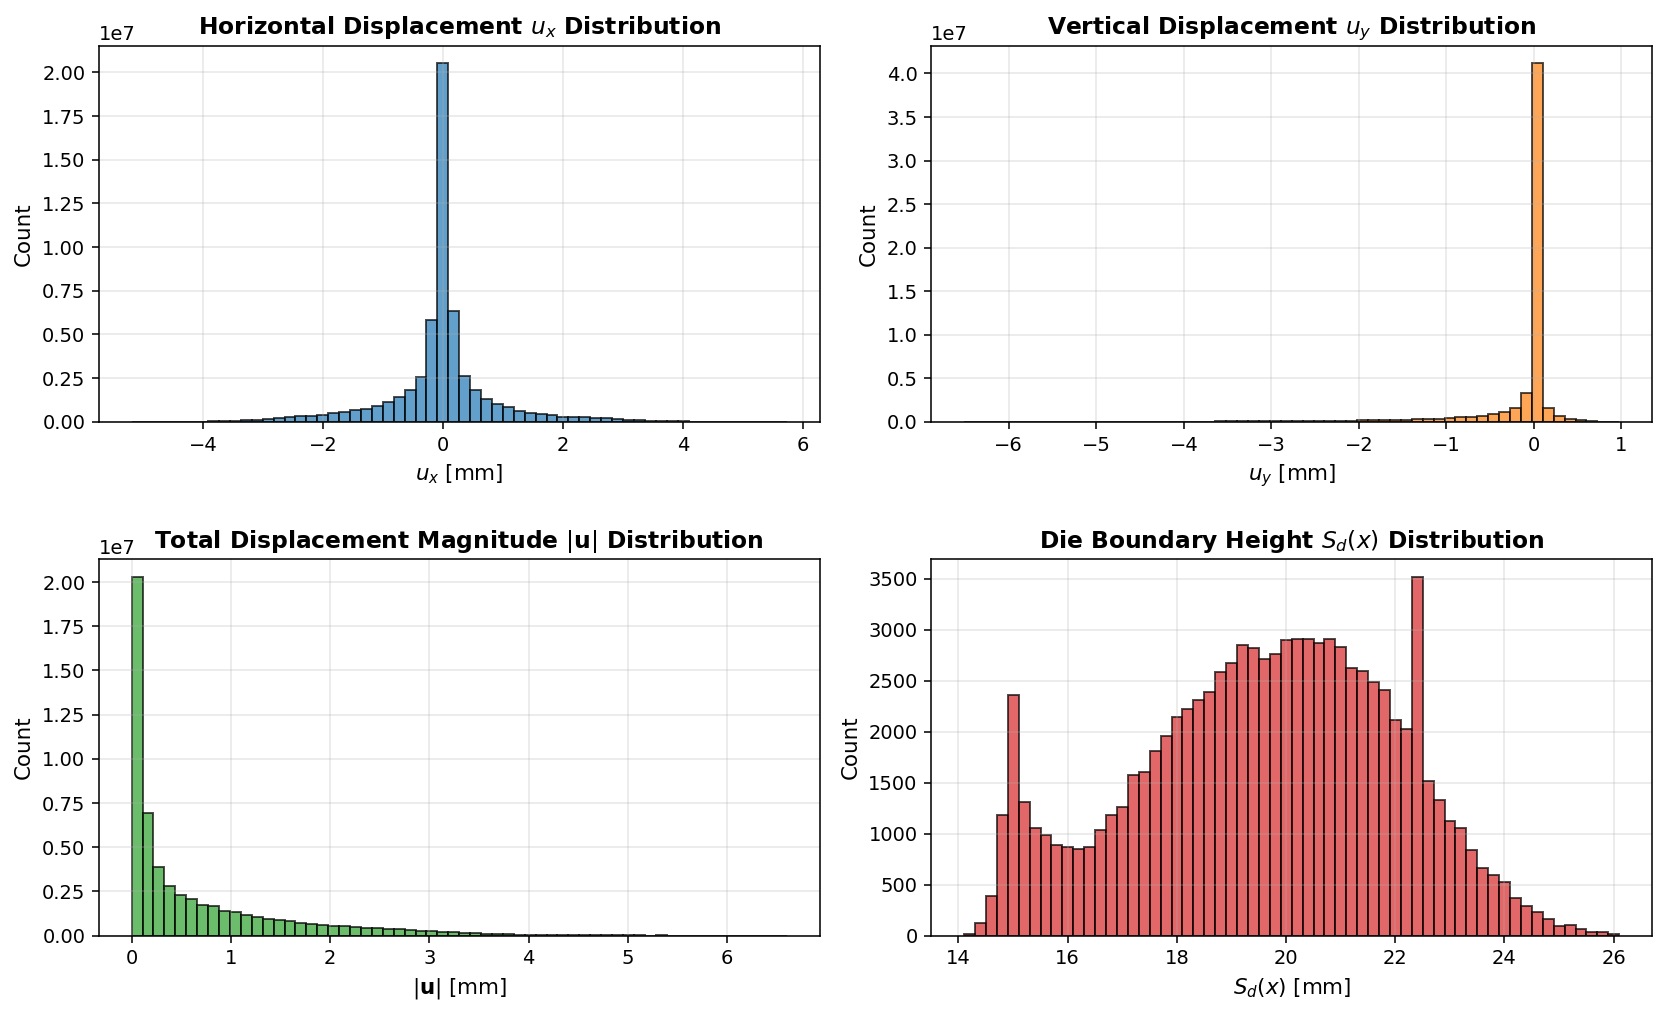

In [8]:
ux_all = displacements[:, :, :, :, 0].flatten()
uy_all = displacements[:, :, :, :, 1].flatten()
umag_all = np.sqrt(ux_all**2 + uy_all**2)
die_all = die_heights.flatten()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

axes[0, 0].hist(ux_all, bins=60, color="#1f77b4", edgecolor="black", alpha=0.7)
axes[0, 0].set_title(r"Horizontal Displacement $u_x$ Distribution", fontweight="bold")
axes[0, 0].set_xlabel("$u_x$ [mm]")
axes[0, 0].set_ylabel("Count")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].hist(uy_all, bins=60, color="#ff7f0e", edgecolor="black", alpha=0.7)
axes[0, 1].set_title(r"Vertical Displacement $u_y$ Distribution", fontweight="bold")
axes[0, 1].set_xlabel("$u_y$ [mm]")
axes[0, 1].set_ylabel("Count")
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].hist(umag_all, bins=60, color="#2ca02c", edgecolor="black", alpha=0.7)
axes[1, 0].set_title(r"Total Displacement Magnitude $|\mathbf{u}|$ Distribution", fontweight="bold")
axes[1, 0].set_xlabel(r"$|\mathbf{u}|$ [mm]")
axes[1, 0].set_ylabel("Count")
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].hist(die_all, bins=60, color="#d62728", edgecolor="black", alpha=0.7)
axes[1, 1].set_title(r"Die Boundary Height $S_d(x)$ Distribution", fontweight="bold")
axes[1, 1].set_xlabel("$S_d(x)$ [mm]")
axes[1, 1].set_ylabel("Count")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. PyTorch DataLoader & Normalization Verification
Testing downstream PyTorch consumption via `PlasticityDataset`:
- Verification of batch generation (`die_boundary`, `query_coords`, `time`, `target`).
- Verification of z-score normalization and round-trip target reconstruction via `denormalize_targets()`.

In [9]:
from src.data.plasticity_dataset import PlasticityDataset, get_plasticity_dataloaders

# Create PyTorch dataset in spatiotemporal query mode
dataset = PlasticityDataset(
    data_dir=DATA_DIR,
    split="train",
    mode="spatiotemporal",
    flatten_spatial=True,
    normalize_inputs=True,
)

print(f"Total Spatiotemporal Items in Train Set: {len(dataset)} (900 samples x 20 timesteps)")

sample_item = dataset[0]
print("\nSample Item Structure:")
for k, v in sample_item.items():
    print(f"  - {k:<14}: shape={str(v.shape):<20} dtype={v.dtype}")

# Test batching through PyTorch DataLoader
loader = torch.utils.data.DataLoader(dataset, batch_size=16, shuffle=True)
batch = next(iter(loader))

print("\nBatch Structure (Batch Size = 16):")
print(f"  - die_boundary: {batch['die_boundary'].shape}")
print(f"  - query_coords: {batch['query_coords'].shape}")
print(f"  - time:         {batch['time'].shape}")
print(f"  - target (norm):{batch['target'].shape}")

# Test denormalization
denorm_target = dataset.denormalize_targets(batch["target"])
print(f"  - target (denorm): {denorm_target.shape}")
print(f"    Target channel 0 (X) physical range: [{denorm_target[..., 0].min():.2f}, {denorm_target[..., 0].max():.2f}] mm")
print(f"    Target channel 1 (Y) physical range: [{denorm_target[..., 1].min():.2f}, {denorm_target[..., 1].max():.2f}] mm")
print("\n✓ DataLoader & normalization verification PASSED!")

Total Spatiotemporal Items in Train Set: 18000 (900 samples x 20 timesteps)

Sample Item Structure:
  - die_boundary  : shape=torch.Size([101, 2]) dtype=torch.float32
  - query_coords  : shape=torch.Size([3131, 2]) dtype=torch.float32
  - time          : shape=torch.Size([1])      dtype=torch.float32
  - target        : shape=torch.Size([3131, 4]) dtype=torch.float32
  - sample_idx    : shape=torch.Size([])       dtype=torch.int64
  - time_idx      : shape=torch.Size([])       dtype=torch.int64

Batch Structure (Batch Size = 16):
  - die_boundary: torch.Size([16, 101, 2])
  - query_coords: torch.Size([16, 3131, 2])
  - time:         torch.Size([16, 1])
  - target (norm):torch.Size([16, 3131, 4])
  - target (denorm): torch.Size([16, 3131, 4])
    Target channel 0 (X) physical range: [-51.14, 4.32] mm
    Target channel 1 (Y) physical range: [-0.10, 14.95] mm

✓ DataLoader & normalization verification PASSED!
